In [1]:
# Cell 1 - Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import SelectKBest, f_regression
import pickle
import warnings
warnings.filterwarnings('ignore')
print("Libraries loaded.")

Libraries loaded.


In [2]:
# Cell 2 - Load Preprocessed Data
train_df = pd.read_csv('../data/processed/train.csv', parse_dates=['Date'])
val_df   = pd.read_csv('../data/processed/val.csv',   parse_dates=['Date'])
test_df  = pd.read_csv('../data/processed/test.csv',  parse_dates=['Date'])
full_df  = pd.read_csv('../data/processed/full_processed.csv', parse_dates=['Date'])
print("Shapes - Train:", train_df.shape, "| Val:", val_df.shape, "| Test:", test_df.shape)

Shapes - Train: (64000, 31) | Val: (13750, 31) | Test: (13500, 31)


In [3]:
# Cell 3 - Lag Features per SKU
def add_lag_features(df, target='Units_Sold', lags=[1, 2, 3, 7, 14, 30]):
    df = df.sort_values(['SKU_ID', 'Date'])
    for lag in lags:
        df[f'lag_{lag}'] = df.groupby('SKU_ID')[target].shift(lag)
    return df

full_df = add_lag_features(full_df)
lag_cols = [c for c in full_df.columns if 'lag_' in c]
print(f"Lag features added ({len(lag_cols)}):", lag_cols)

Lag features added (6): ['lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_30']


In [4]:
# Cell 4 - Rolling Window Statistics per SKU
def add_rolling_features(df, target='Units_Sold', windows=[7, 14, 30]):
    df = df.sort_values(['SKU_ID', 'Date'])
    for win in windows:
        df[f'rolling_mean_{win}'] = df.groupby('SKU_ID')[target].transform(
            lambda x: x.shift(1).rolling(win, min_periods=1).mean())
        df[f'rolling_std_{win}']  = df.groupby('SKU_ID')[target].transform(
            lambda x: x.shift(1).rolling(win, min_periods=1).std().fillna(0))
        df[f'rolling_max_{win}']  = df.groupby('SKU_ID')[target].transform(
            lambda x: x.shift(1).rolling(win, min_periods=1).max())
        df[f'rolling_min_{win}']  = df.groupby('SKU_ID')[target].transform(
            lambda x: x.shift(1).rolling(win, min_periods=1).min())
    return df

full_df = add_rolling_features(full_df)
roll_cols = [c for c in full_df.columns if 'rolling_' in c]
print(f"Rolling features added ({len(roll_cols)}):", roll_cols)

Rolling features added (12): ['rolling_mean_7', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'rolling_mean_14', 'rolling_std_14', 'rolling_max_14', 'rolling_min_14', 'rolling_mean_30', 'rolling_std_30', 'rolling_max_30', 'rolling_min_30']


In [5]:
# Cell 5 - Exponential Weighted Mean (EWM) Features
def add_ewm_features(df, target='Units_Sold', spans=[7, 14, 30]):
    df = df.sort_values(['SKU_ID', 'Date'])
    for span in spans:
        df[f'ewm_{span}'] = df.groupby('SKU_ID')[target].transform(
            lambda x: x.shift(1).ewm(span=span, adjust=False).mean())
    return df

full_df = add_ewm_features(full_df)
ewm_cols = [c for c in full_df.columns if 'ewm_' in c]
print(f"EWM features added ({len(ewm_cols)}):", ewm_cols)

EWM features added (3): ['ewm_7', 'ewm_14', 'ewm_30']


In [6]:
# Cell 6 - Business-Derived Features
full_df['inventory_ratio']   = full_df['Inventory_Level'] / (full_df['Reorder_Point'] + 1e-5)
full_df['price_margin']      = full_df['Unit_Price'] - full_df['Unit_Cost']
full_df['lead_time_x_order'] = full_df['Supplier_Lead_Time_Days'] * full_df['Order_Quantity']
full_df['stockout_risk']     = (full_df['Inventory_Level'] < full_df['Reorder_Point']).astype(int)
print("Derived business features added:")
print("  inventory_ratio, price_margin, lead_time_x_order, stockout_risk")
print("New shape:", full_df.shape)

Derived business features added:
  inventory_ratio, price_margin, lead_time_x_order, stockout_risk
New shape: (91250, 56)


In [7]:
# Cell 7 - Drop NaN Rows Introduced by Lag Features
lag_roll_cols = [c for c in full_df.columns if 'lag_' in c or 'rolling_' in c]
full_df = full_df.dropna(subset=lag_roll_cols).reset_index(drop=True)
print("Shape after dropping NaN rows:", full_df.shape)

Shape after dropping NaN rows: (89750, 56)


In [8]:
# Cell 8 - Feature Importance via SelectKBest (F-Regression)
exclude = ['Date', 'SKU_ID', 'Warehouse_ID', 'Supplier_ID', 'Region', 'Units_Sold', 'Units_Sold_scaled']
feature_cols = [c for c in full_df.columns if c not in exclude]
X = full_df[feature_cols].fillna(0)
y = full_df['Units_Sold']

selector = SelectKBest(f_regression, k='all')
selector.fit(X, y)
scores = pd.Series(selector.scores_, index=feature_cols).sort_values(ascending=False)
print("Top 20 features by F-score:")
print(scores.head(20).to_string())

Top 20 features by F-score:
Demand_Forecast    822206.201856
rolling_mean_30    157403.468621
ewm_30             157322.976620
rolling_mean_14    149871.172481
ewm_14             149840.570741
ewm_7              136538.177022
rolling_mean_7     136371.098784
Month_sin          134128.482788
rolling_min_30     125110.830849
rolling_min_14     118648.638988
rolling_max_30     113743.922996
rolling_min_7      108333.963505
rolling_max_14     108181.419201
rolling_max_7       99053.928891
Quarter             67867.033086
lag_2               66101.125876
lag_14              66020.244468
lag_3               65776.246663
lag_1               65522.947265
lag_7               65345.248789


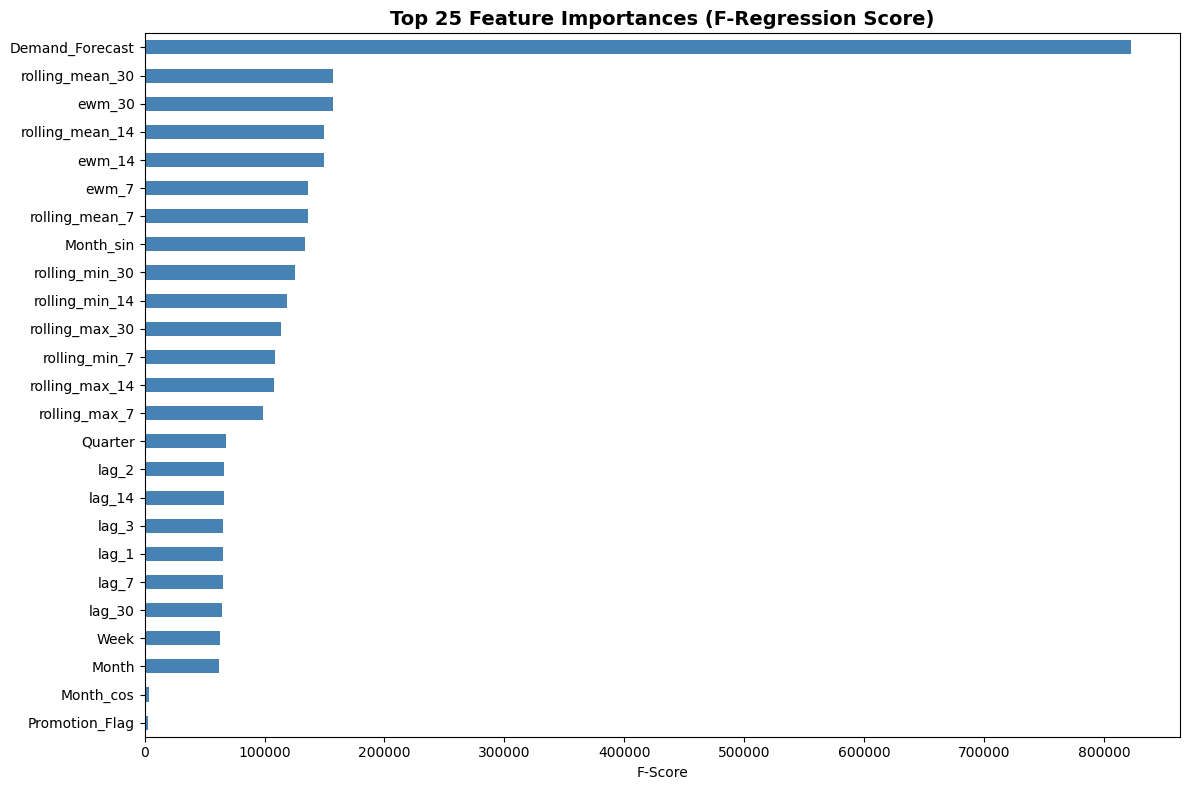

In [9]:
# Cell 9 - Feature Importance Plot
import os
os.makedirs('../outputs/plots', exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 8))
scores.head(25).sort_values().plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Top 25 Feature Importances (F-Regression Score)', fontsize=14, fontweight='bold')
ax.set_xlabel('F-Score')
plt.tight_layout()
plt.savefig('../outputs/plots/03_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# Cell 10 - Sequence Dataset Helper Function
def create_sequences(data, feature_cols, target_col, seq_length=30):
    """Create sliding window sequences for LSTM/GRU input."""
    X_seqs, y_seqs = [], []
    for sku in sorted(data['SKU_ID'].unique()):
        sku_data = data[data['SKU_ID'] == sku].sort_values('Date')
        X = sku_data[feature_cols].fillna(0).values
        y = sku_data[target_col].values
        for i in range(seq_length, len(X)):
            X_seqs.append(X[i - seq_length:i])
            y_seqs.append(y[i])
    return np.array(X_seqs, dtype=np.float32), np.array(y_seqs, dtype=np.float32)

print("create_sequences() helper defined.")
print(f"Example usage: X, y = create_sequences(df, feature_cols, 'Units_Sold_scaled', seq_length=30)")

create_sequences() helper defined.
Example usage: X, y = create_sequences(df, feature_cols, 'Units_Sold_scaled', seq_length=30)


In [11]:
# Cell 11 - Save Engineered Dataset & Top Features
top_features = scores.head(30).index.tolist()
print(f"Final feature set ({len(top_features)} features):")
for i, f in enumerate(top_features, 1):
    print(f"  {i:2d}. {f}")

full_df.to_csv('../data/processed/full_engineered.csv', index=False)

with open('../data/processed/top_features.pkl', 'wb') as f:
    pickle.dump(top_features, f)

print("\n✅ Feature Engineering Complete!")
print("Saved: data/processed/full_engineered.csv")
print("Saved: data/processed/top_features.pkl")

Final feature set (30 features):
   1. Demand_Forecast
   2. rolling_mean_30
   3. ewm_30
   4. rolling_mean_14
   5. ewm_14
   6. ewm_7
   7. rolling_mean_7
   8. Month_sin
   9. rolling_min_30
  10. rolling_min_14
  11. rolling_max_30
  12. rolling_min_7
  13. rolling_max_14
  14. rolling_max_7
  15. Quarter
  16. lag_2
  17. lag_14
  18. lag_3
  19. lag_1
  20. lag_7
  21. lag_30
  22. Week
  23. Month
  24. Month_cos
  25. Promotion_Flag
  26. rolling_std_30
  27. rolling_std_14
  28. rolling_std_7
  29. Order_Quantity
  30. Inventory_Level

✅ Feature Engineering Complete!
Saved: data/processed/full_engineered.csv
Saved: data/processed/top_features.pkl
